# Observing gender_ukr.csv

In [2]:
%pip install missingno


[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import missingno as msno
import seaborn as sns

data = pd.read_csv("../data/raw/gender_ukr.csv")
h=data.head()
display(h)
print("Shape:", data.shape)

,Country Name,Country ISO3,Year,Indicator Name,Indicator Code,Value
0,Ukraine,UKR,2019,Firms with female top manager (% of firms),IC.FRM.FEMM.ZS,17.679892
1,Ukraine,UKR,2013,Firms with female top manager (% of firms),IC.FRM.FEMM.ZS,20.894083
2,Ukraine,UKR,2008,Firms with female top manager (% of firms),IC.FRM.FEMM.ZS,27.912994
3,Ukraine,UKR,2019,Firms with female participation in ownership (...,IC.FRM.FEMO.ZS,38.567986
4,Ukraine,UKR,2013,Firms with female participation in ownership (...,IC.FRM.FEMO.ZS,32.208115


Shape: (3808, 6)


Country Name      0
Country ISO3      0
Year              0
Indicator Name    0
Indicator Code    0
Value             0
dtype: int64

<Axes: >

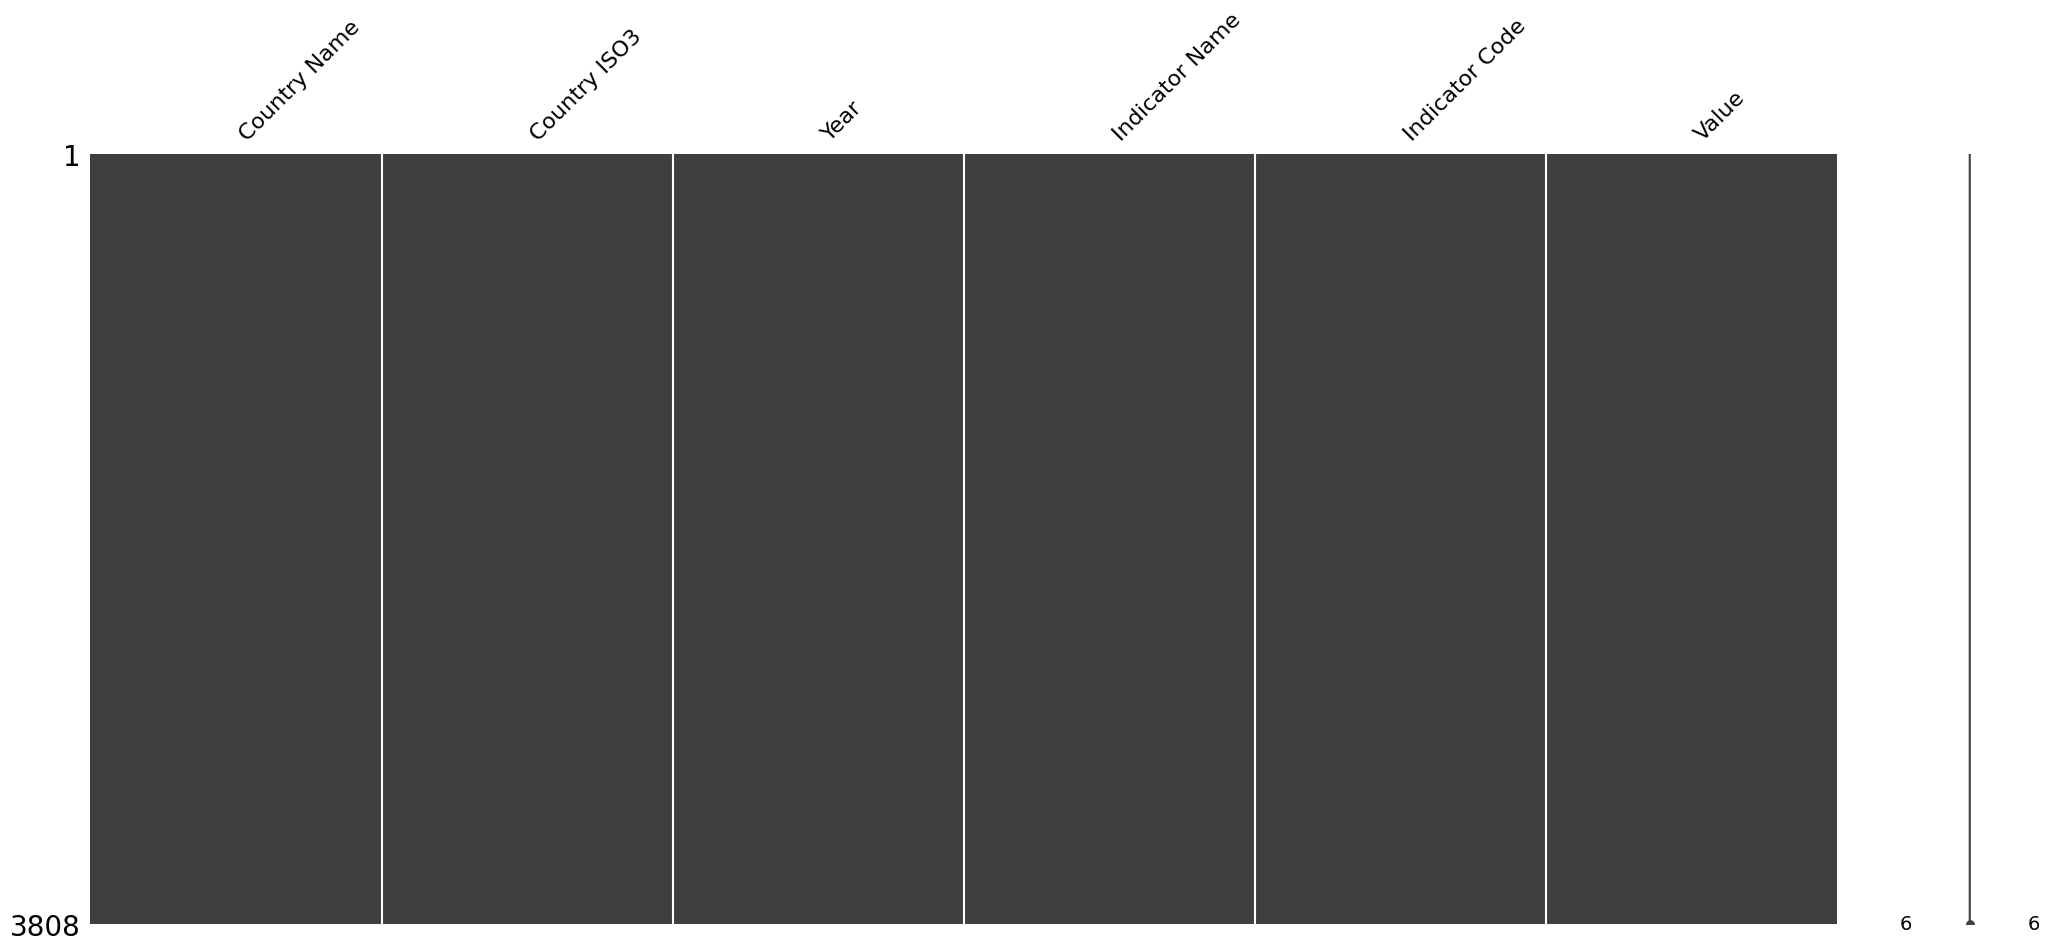

In [4]:
display(data.isna().sum())
msno.matrix(data)

In [5]:
data["Year"] = pd.to_numeric(data["Year"])
print("YEAR SORTED")
display(data.sort_values("Year", ascending=True))

YEAR SORTED


,Country Name,Country ISO3,Year,Indicator Name,Indicator Code,Value
3029,Ukraine,UKR,1960,"Age population, age 00, female",SP.POP.AG00.FE.IN,418001.000000
2507,Ukraine,UKR,1960,"Survival to age 65, male (% of cohort)",SP.DYN.TO65.MA.ZS,65.572914
2312,Ukraine,UKR,1960,"Life expectancy at birth, male (years)",SP.DYN.LE00.MA.IN,65.912000
2247,Ukraine,UKR,1960,"Life expectancy at birth, female (years)",SP.DYN.LE00.FE.IN,71.989000
3557,Ukraine,UKR,1960,"Age population, age 04, female",SP.POP.AG04.FE.IN,386196.000000
...,...,...,...,...,...,...
3426,Ukraine,UKR,2025,"Age population, age 03, male",SP.POP.AG03.MA.IN,134710.000000
3030,Ukraine,UKR,2025,"Age population, age 00, male",SP.POP.AG00.MA.IN,126342.000000
3162,Ukraine,UKR,2025,"Age population, age 01, male",SP.POP.AG01.MA.IN,129091.000000
3624,Ukraine,UKR,2025,"Age population, age 05, female",SP.POP.AG05.FE.IN,158963.000000


In [6]:
data.describe()
# data['Value'] = np.log( pd.to_numeric(data["Value"]) )
# data.describe()



,Year,Value
count,3808.000000,3.808000e+03
mean,2001.226103,1.588832e+05
std,15.480589,1.036350e+06
min,1960.000000,0.000000e+00
25%,1993.000000,1.945201e+01
50%,2004.000000,6.713300e+01
75%,2013.000000,2.547375e+02
max,2025.000000,1.204811e+07


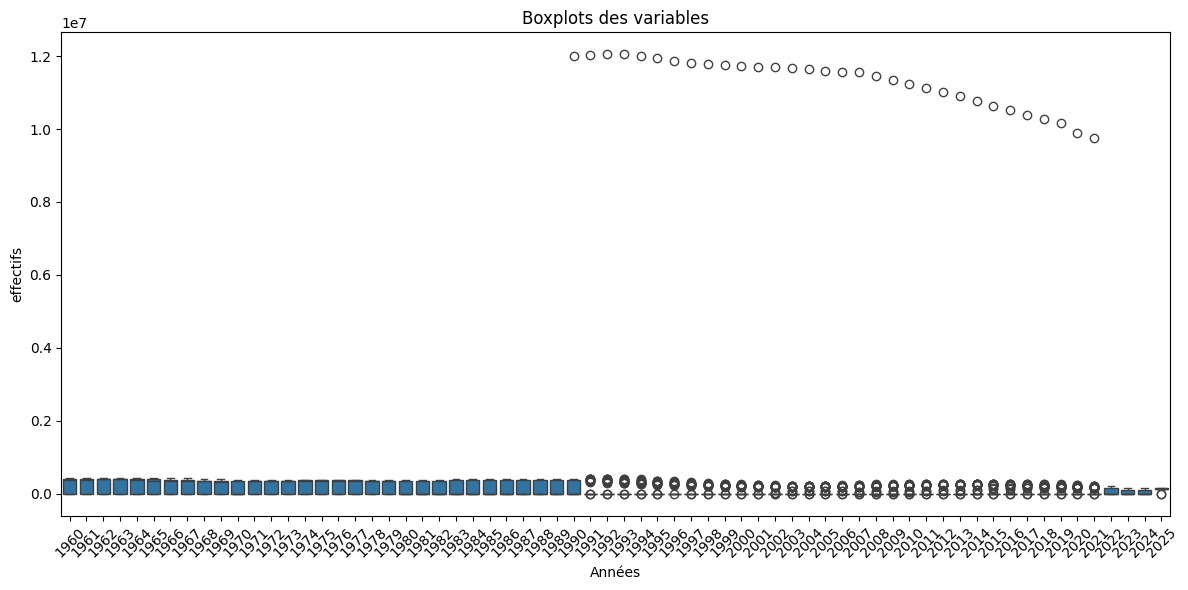

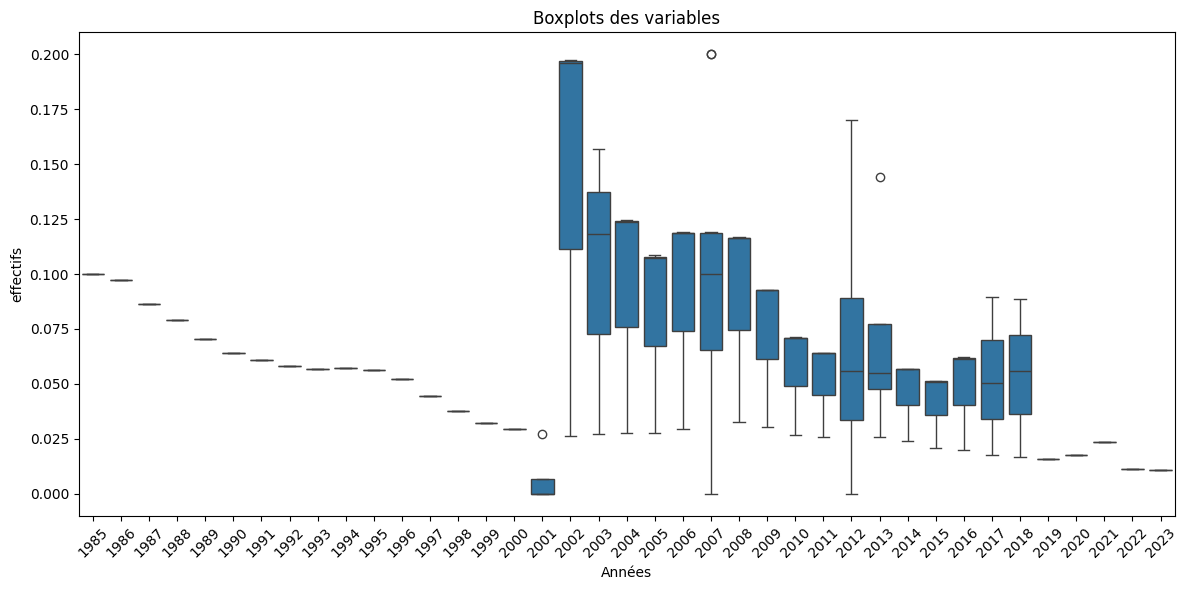

In [7]:
plt.figure(figsize=(12, 6)) #lines, columns

sns.boxplot(data, x = "Year", y="Value")
plt.xlabel("Années")
plt.ylabel("effectifs")
plt.title("Boxplots des variables")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


data_val_reduce =  data[data["Value"].between(0, 0.2)]
plt.figure(figsize=(12, 6)) #lines, columns

sns.boxplot(data_val_reduce, x = "Year", y="Value")
plt.xlabel("Années")
plt.ylabel("effectifs")
plt.title("Boxplots des variables")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


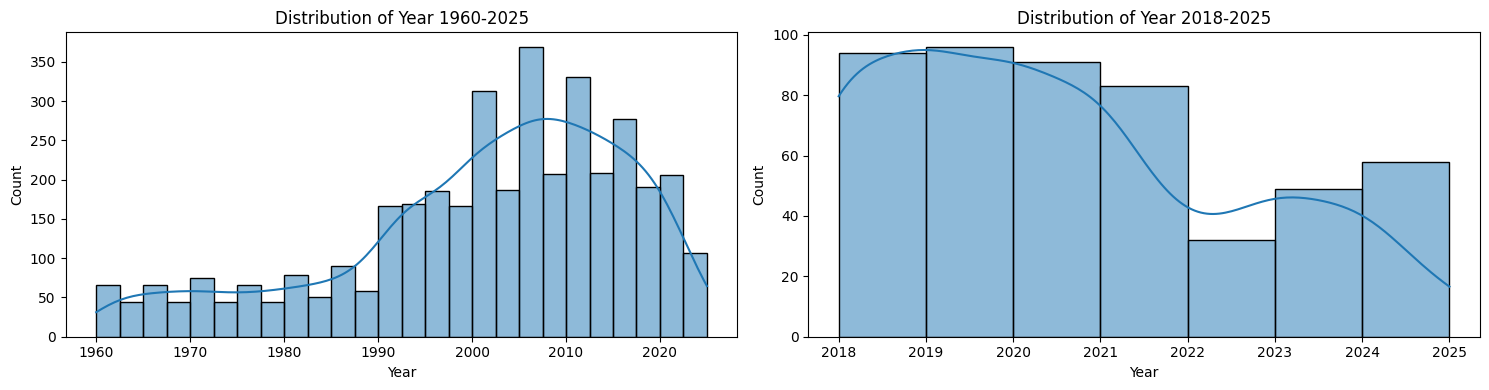

In [8]:
data_2018_2025 = data[data["Year"].between(2018, 2025)]
fig, axes = plt.subplots(1, 2, figsize=(15, 4 * 1))
axes_flat = axes.ravel()
sns.histplot(data, x="Year", kde=True, ax=axes_flat[0]) #x is column name, kde=True overlays a smooth curve on top of the bar (density), ax=axes_flat[i] where to draw that curve
axes_flat[0].set_title(f"Distribution of Year 1960-2025")
sns.histplot(data_2018_2025, x="Year",binwidth=1, kde=True, ax=axes_flat[1]) #x is column name, kde=True overlays a smooth curve on top of the bar (density), ax=axes_flat[i] where to draw that curve
axes_flat[1].set_title(f"Distribution of Year 2018-2025")

# Adjust spacing to prevent overlapping labels
plt.tight_layout()
plt.show()


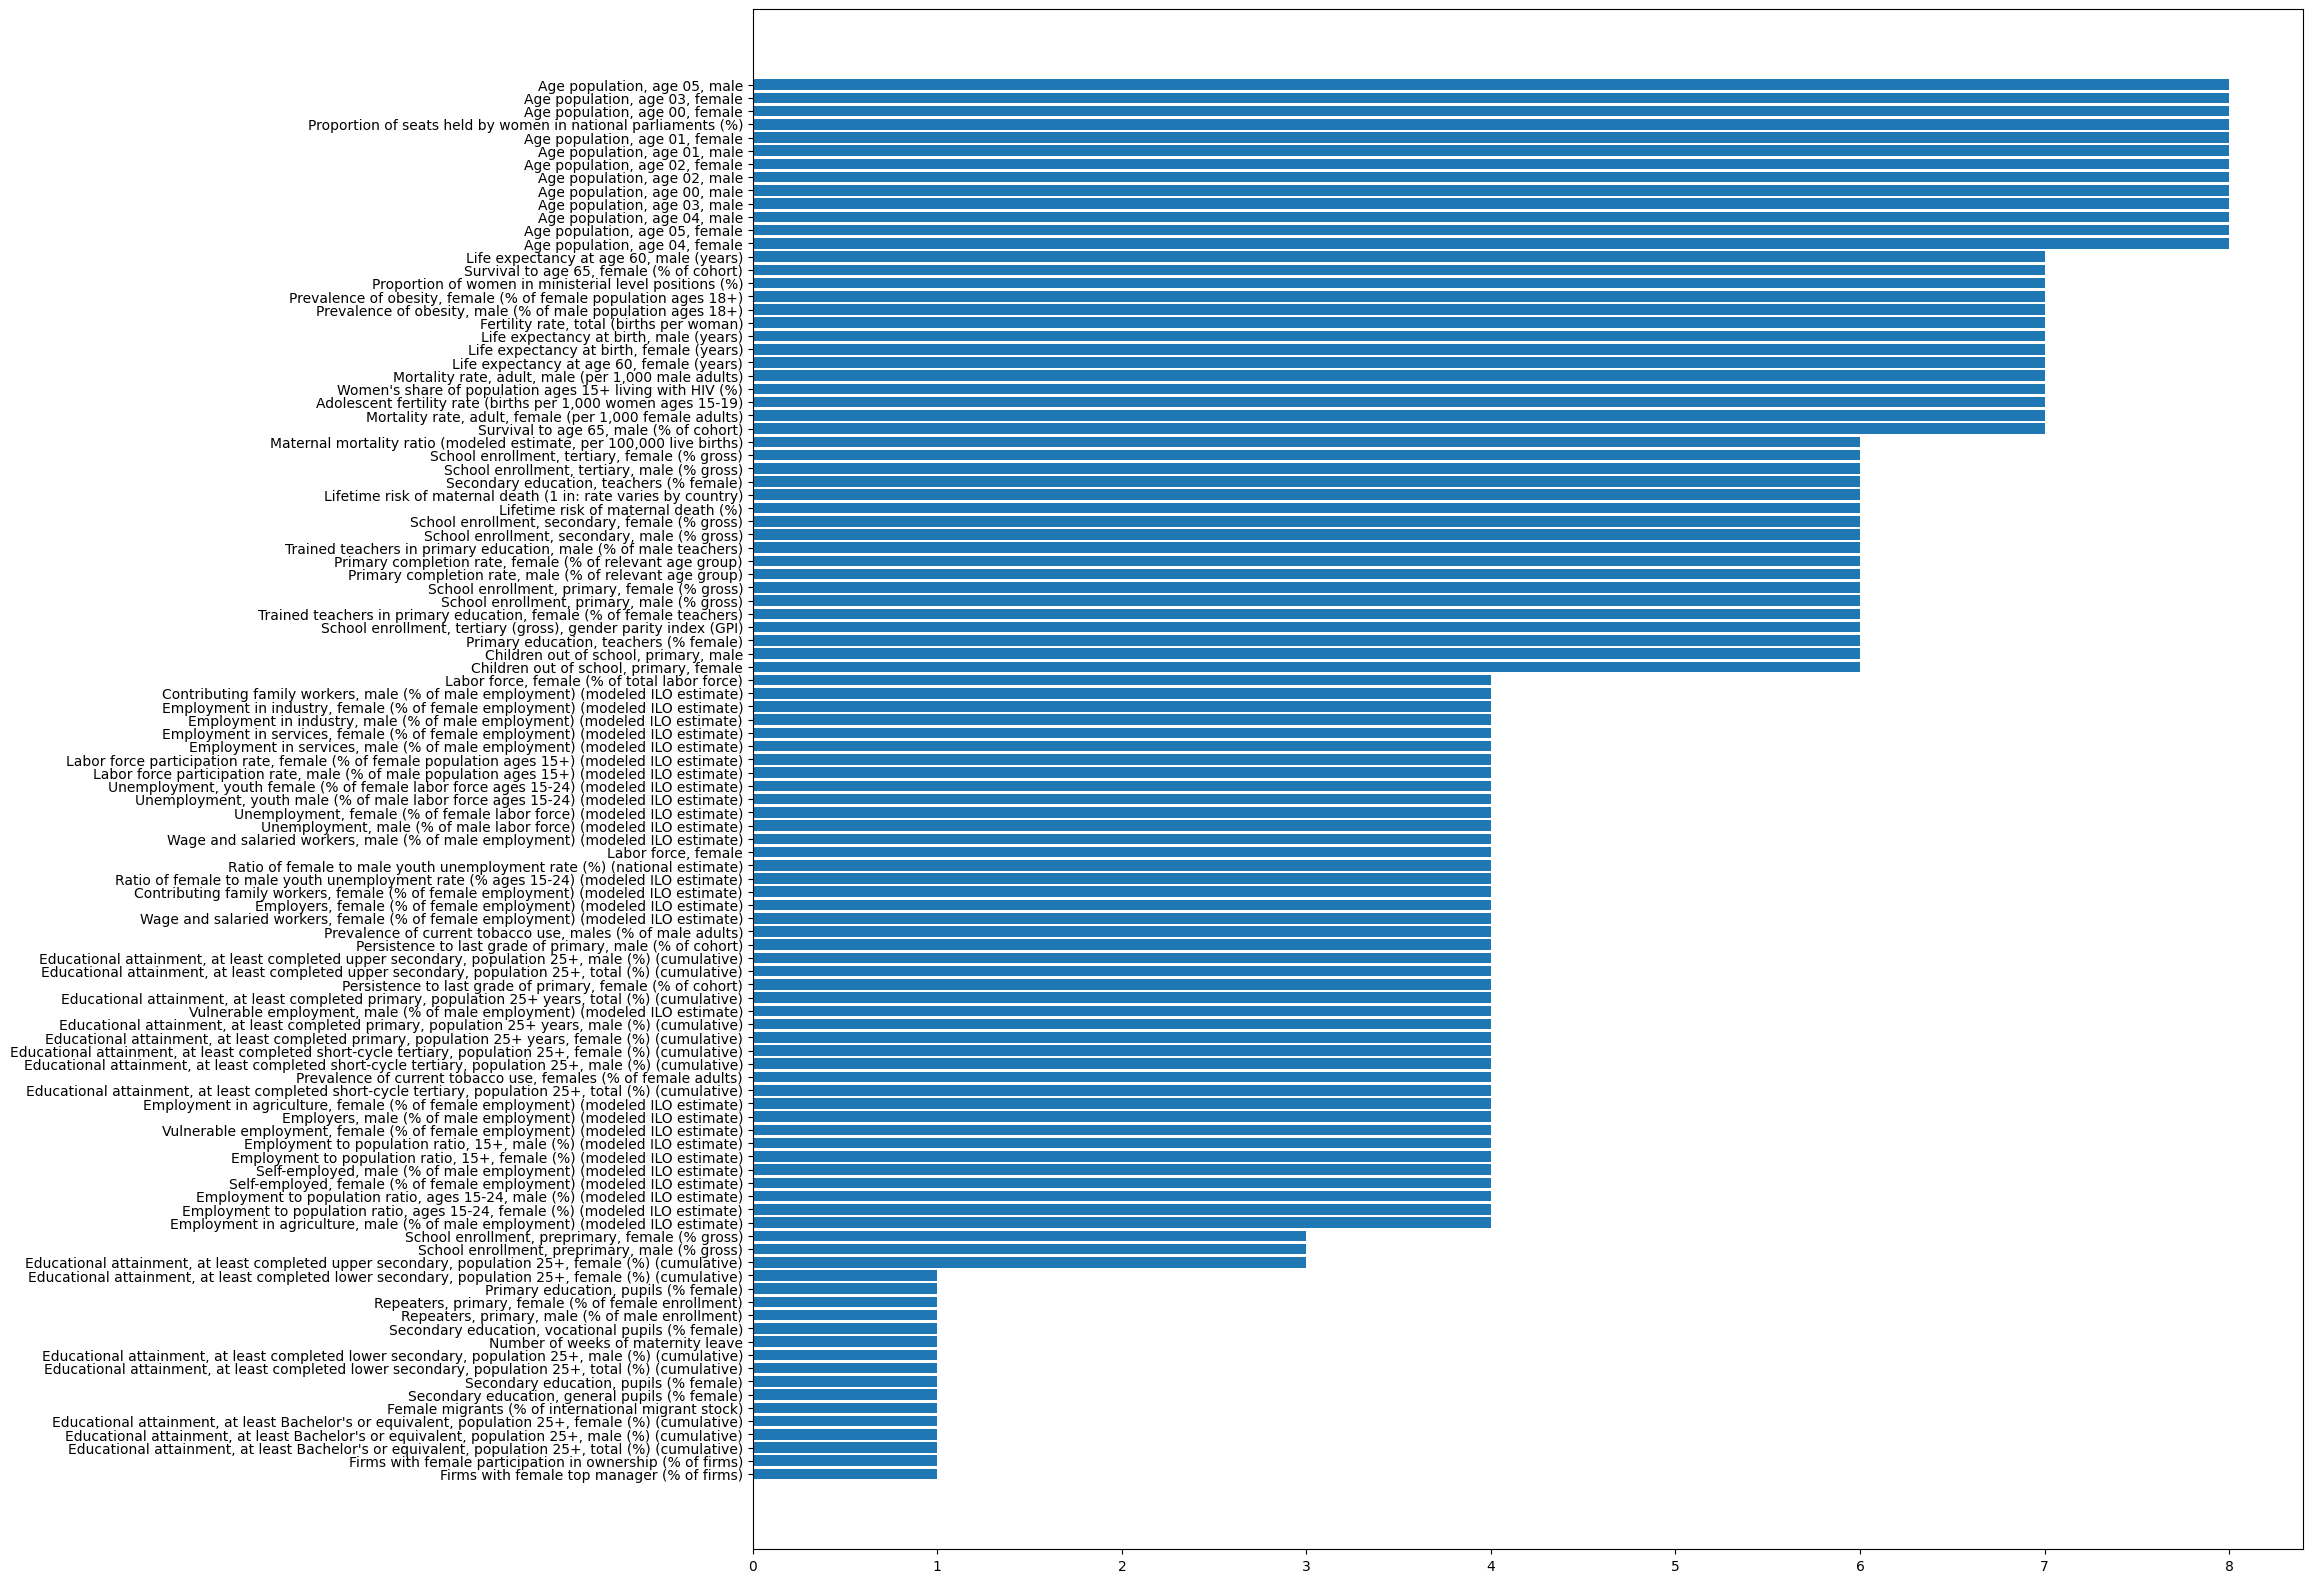

In [9]:
plt.figure(figsize=(20, 20))
counts = data_2018_2025["Indicator Name"].value_counts()
names = [name for name in counts.index]
# plt.bar(counts.index, counts.values)
# plt.xticks(range(len(counts)), names, rotation=90)
# plt.show()

# Use barh for a horizontal bar chart
plt.barh(counts.index, counts.values)
# Put the names on the y-ticks (no rotation needed)
plt.yticks(range(len(counts)), names)
# Invert y-axis so the highest count appears at the top
plt.gca().invert_yaxis()
plt.show()


In [10]:
print("Number of unique indicators", len(counts))


Number of unique indicators 106


## Main observations
The table contains 3808 rows and 6 columns. Data does not have any missing values. 
### Year
- The minimum value is 1960 and the maximum is 2025. As we have other datasets that are not available until 2018/2019, we will keep only 2018-2025 years.
- We could analyse which indicator(s) is(are) the most represented through all years to make sure to have enough of information for each year.
### Indicators
- We have 106 unique indicators. Their values are different depending on the indicator itself, so we should be careful not to mix, for example, percentages with other quantitative values such as total population number.
- Indicators with the least number of values are "Educational atteinment ..." and "Firms with female top manager", so we won't keep them, especially the first since we already have a preprocessed dataset on education. However, there are some educational atteinment with enough values which we could analyse in addition to our preprocessed set on education in so far as there are only enrollmeent/graduation indicators in it, but not the atteinment.
- We could also see if we can't generelize some information for the indicators with the same meaning but slight differences (age population 00/age population 02 ...)
### --- Conclusion ----
- This dataset is rather qualitative addition (has lots of qualitative indicators ) so maybe it's better to keep most of the indicators to have diverse points to analize later.
Next steps:
1. Keep only 2018-2025
2. Sort by year
3. Delete indicatiors with least value counts.


# Preprocessing

In [11]:
data_2018_2025 = data[data["Year"].between(2018, 2025)]
display(data_2018_2025)
print("Shape:", data_2018_2025.shape)

,Country Name,Country ISO3,Year,Indicator Name,Indicator Code,Value
0,Ukraine,UKR,2019,Firms with female top manager (% of firms),IC.FRM.FEMM.ZS,17.679892
3,Ukraine,UKR,2019,Firms with female participation in ownership (...,IC.FRM.FEMO.ZS,38.567986
68,Ukraine,UKR,2024,"School enrollment, tertiary (gross), gender pa...",SE.ENR.TERT.FM.ZS,0.853950
69,Ukraine,UKR,2023,"School enrollment, tertiary (gross), gender pa...",SE.ENR.TERT.FM.ZS,0.987550
70,Ukraine,UKR,2021,"School enrollment, tertiary (gross), gender pa...",SE.ENR.TERT.FM.ZS,1.114710
...,...,...,...,...,...,...
3693,Ukraine,UKR,2022,"Age population, age 05, male",SP.POP.AG05.MA.IN,198871.000000
3694,Ukraine,UKR,2021,"Age population, age 05, male",SP.POP.AG05.MA.IN,226116.000000
3695,Ukraine,UKR,2020,"Age population, age 05, male",SP.POP.AG05.MA.IN,238505.000000
3696,Ukraine,UKR,2019,"Age population, age 05, male",SP.POP.AG05.MA.IN,254709.000000


Shape: (503, 6)


In [12]:
data_2018_2025_sorted = data_2018_2025.sort_values("Year", ascending=True)
display(data_2018_2025_sorted)


,Country Name,Country ISO3,Year,Indicator Name,Indicator Code,Value
3697,Ukraine,UKR,2018,"Age population, age 05, male",SP.POP.AG05.MA.IN,265625.000000
1572,Ukraine,UKR,2018,"Contributing family workers, female (% of fema...",SL.FAM.WORK.FE.ZS,5.353274
598,Ukraine,UKR,2018,"Educational attainment, at least completed upp...",SE.SEC.CUAT.UP.MA.ZS,75.528558
1603,Ukraine,UKR,2018,"Contributing family workers, male (% of male e...",SL.FAM.WORK.MA.ZS,2.434488
1634,Ukraine,UKR,2018,"Employment in industry, female (% of female em...",SL.IND.EMPL.FE.ZS,13.672506
...,...,...,...,...,...,...
3360,Ukraine,UKR,2025,"Age population, age 03, female",SP.POP.AG03.FE.IN,129442.000000
3492,Ukraine,UKR,2025,"Age population, age 04, female",SP.POP.AG04.FE.IN,151408.000000
2577,Ukraine,UKR,2025,Proportion of women in ministerial level posit...,SG.GEN.MNST.ZS,20.000000
3162,Ukraine,UKR,2025,"Age population, age 01, male",SP.POP.AG01.MA.IN,129091.000000


In [13]:
# Count total occurrences (rows) for each indicator
row_counts = data_2018_2025_sorted['Indicator Name'].value_counts()
# Get the indicators with the least count (e.g., bottom 10)
least_frequent_indicators = row_counts.tail(43-26)
print('Indicators with the least count:')
print(least_frequent_indicators)


Indicators with the least count:
Indicator Name
School enrollment, preprimary, female (% gross)                                                        3
Secondary education, pupils (% female)                                                                 1
Educational attainment, at least completed lower secondary, population 25+, female (%) (cumulative)    1
Secondary education, vocational pupils (% female)                                                      1
Female migrants (% of international migrant stock)                                                     1
Firms with female participation in ownership (% of firms)                                              1
Educational attainment, at least Bachelor's or equivalent, population 25+, female (%) (cumulative)     1
Educational attainment, at least completed lower secondary, population 25+, total (%) (cumulative)     1
Educational attainment, at least completed lower secondary, population 25+, male (%) (cumulative)      1
Educati

In [14]:
# 3. Identifier les indicateurs à garder (ceux qui ont un count supérieur à 3)
valid_indicators = row_counts[row_counts > 4].index

# 4. Filtrer le DataFrame pour ne garder que ces indicateurs
df_filtered = data_2018_2025_sorted[data_2018_2025_sorted['Indicator Name'].isin(valid_indicators)]
row_filtered = df_filtered['Indicator Name'].value_counts()
row_unfiltered = data['Indicator Name'].value_counts()

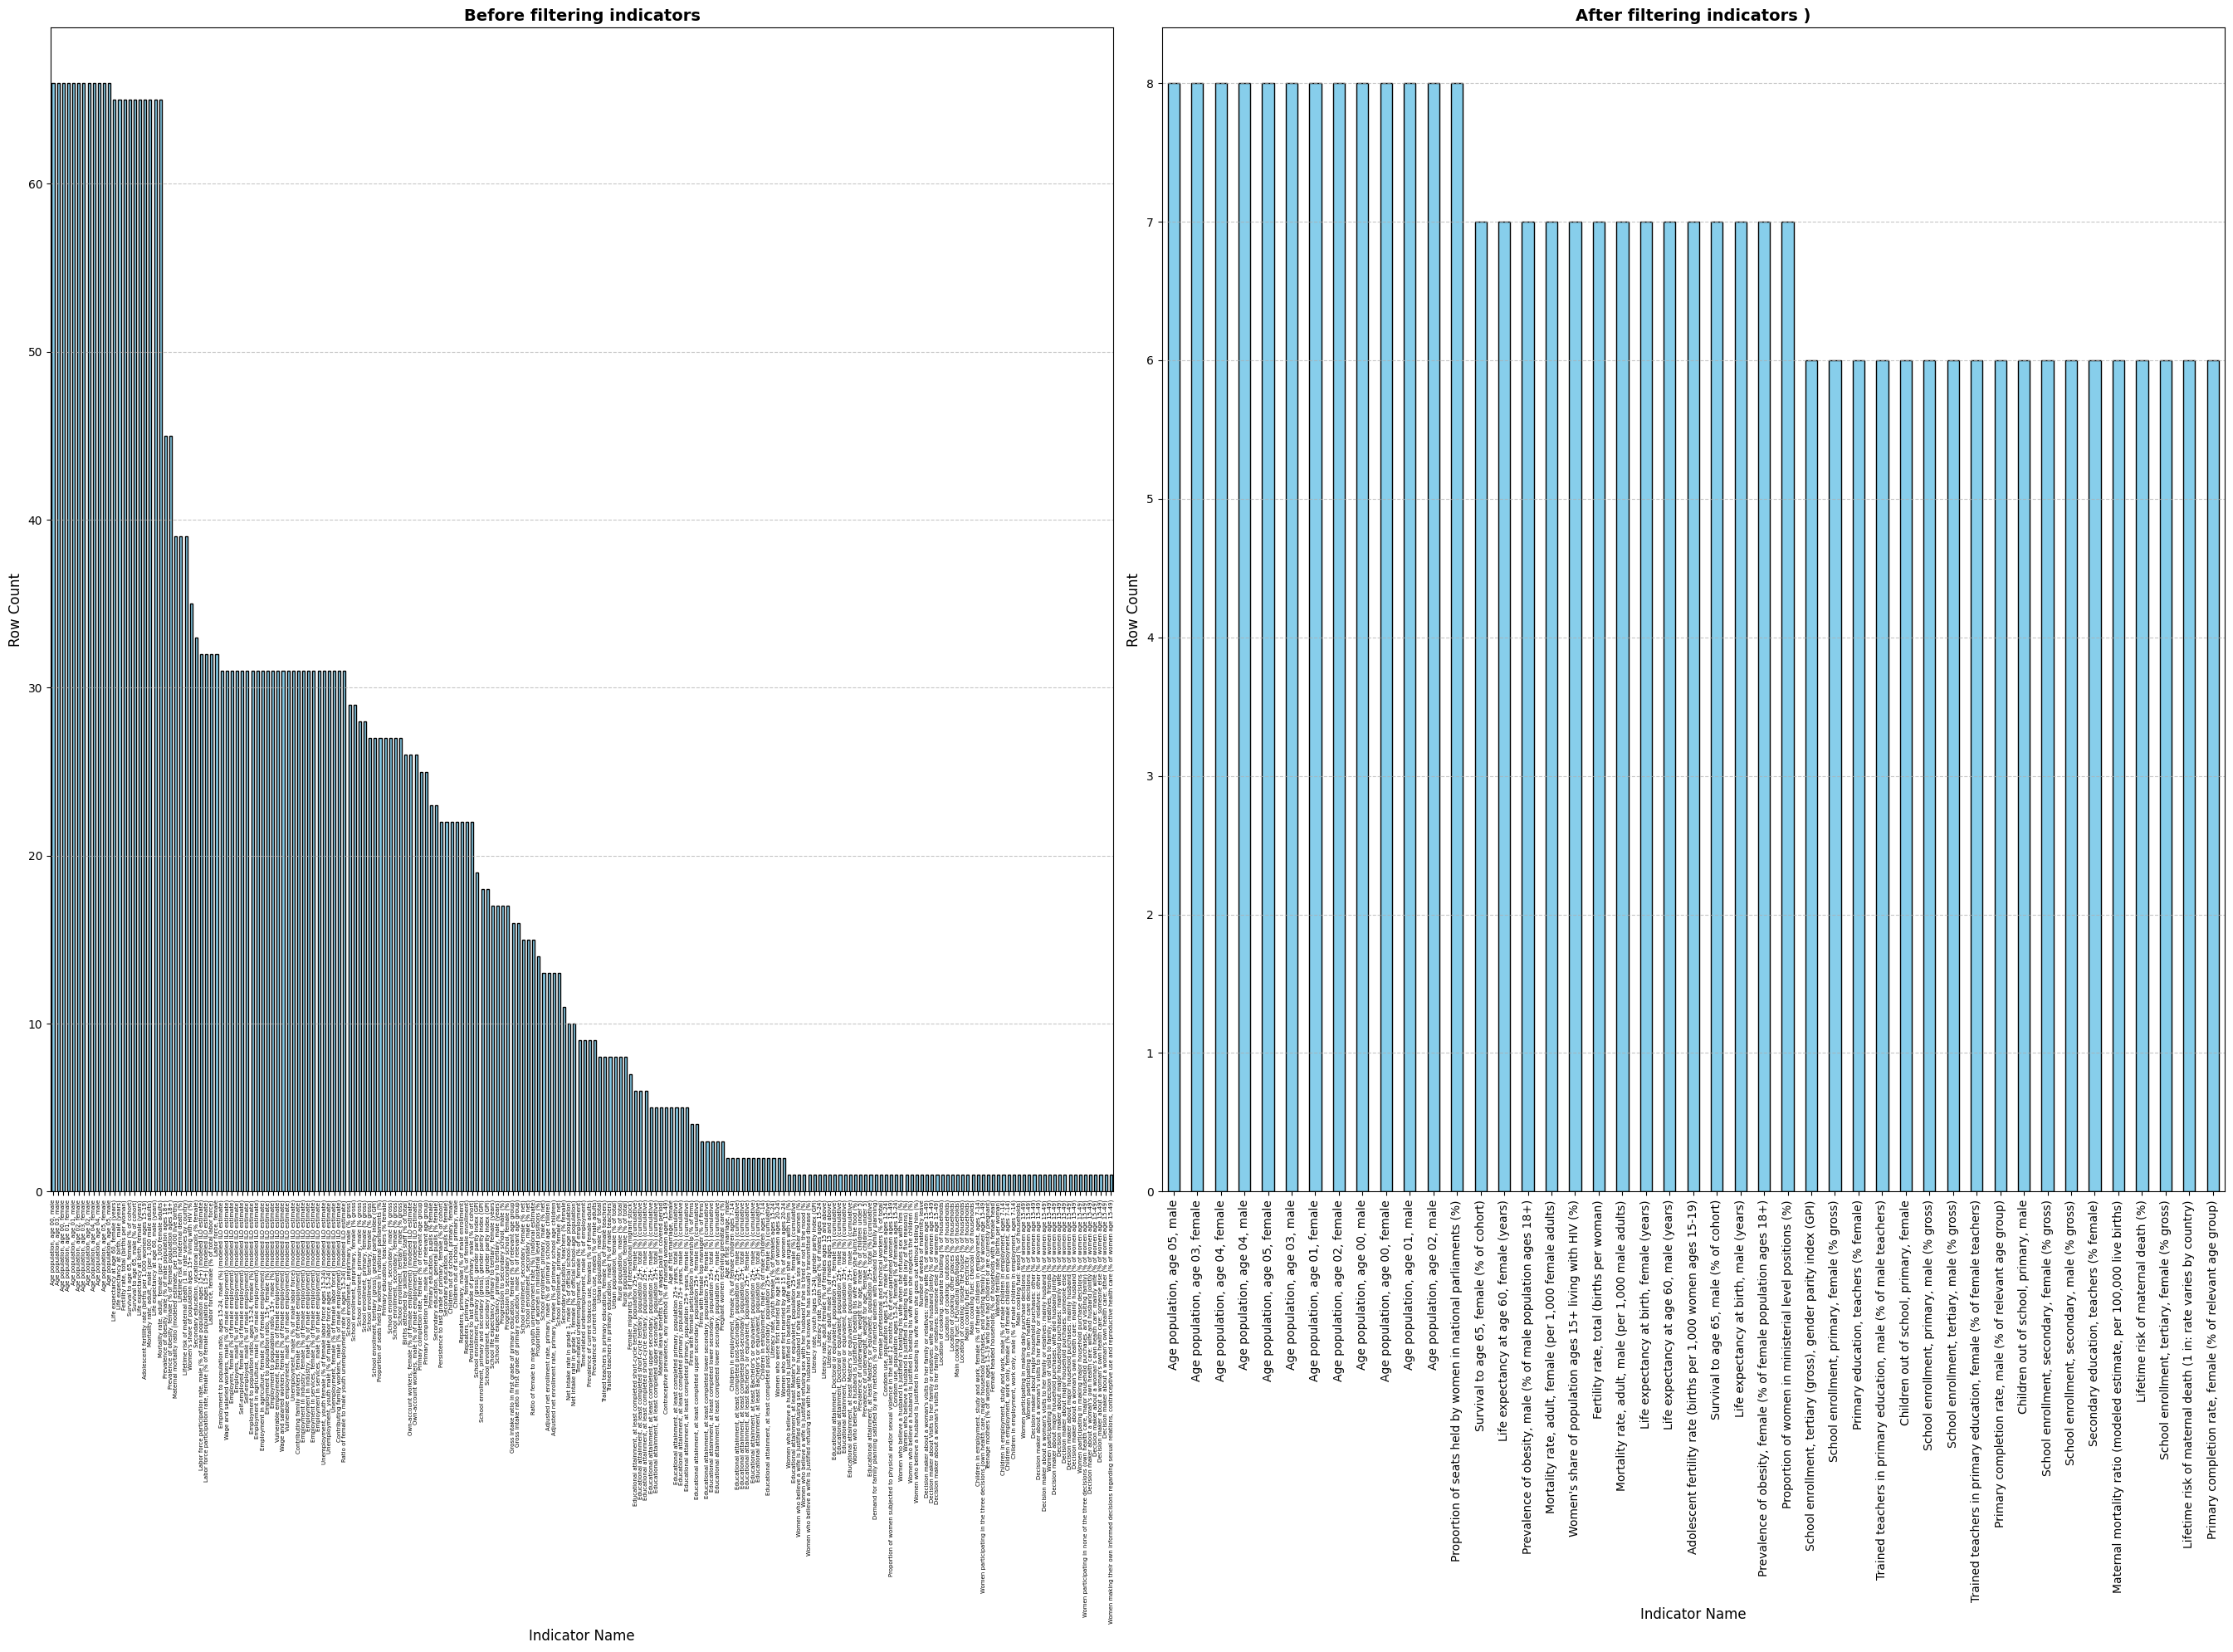

In [15]:
# 1. Créer une figure avec 1 ligne et 2 colonnes
fig, axes = plt.subplots(1, 2, figsize=(27, 20))

# --- Graphique 1 : AVANT (DataFrame de base) ---
row_unfiltered.plot(
    kind='bar', ax=axes[0], color='skyblue', edgecolor='black'
)
axes[0].set_title(
    'Before filtering indicators', fontsize=14, fontweight='bold'
)
axes[0].set_xlabel('Indicator Name', fontsize=12)
axes[0].set_ylabel('Row Count', fontsize=12)
axes[0].tick_params(axis='x', rotation=90, labelsize=5)
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# --- Graphique 2 : APRÈS (DataFrame filtré) ---
row_filtered.plot(
    kind='bar', ax=axes[1], color='skyblue', edgecolor='black'
)
axes[1].set_title(
    'After filtering indicators )', fontsize=14, fontweight='bold'
)
axes[1].set_xlabel('Indicator Name', fontsize=12)
axes[1].set_ylabel('Row Count', fontsize=12)
axes[1].tick_params(axis='x', rotation=90)
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

# Ajuster l'espacement et afficher
plt.tight_layout()
plt.show()

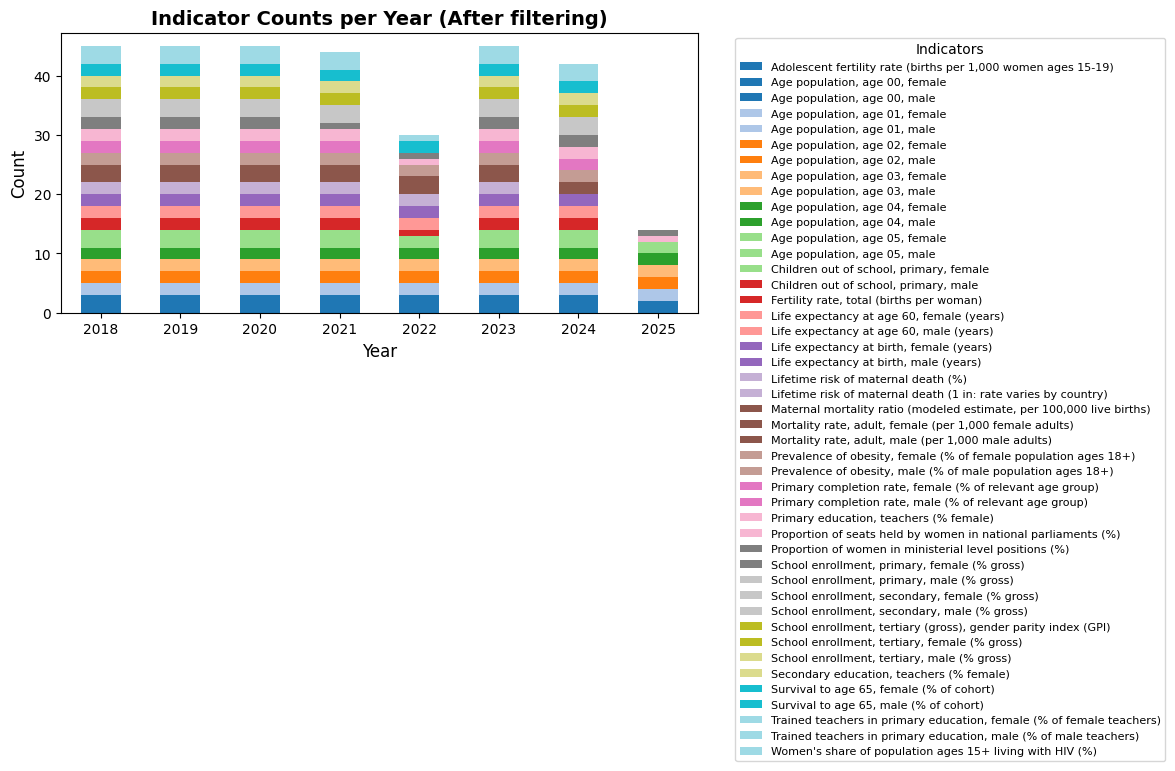

Shape (310, 6)


/var/folders/d3/_3prq75j4zs7ww42zcnxc6bw0000gn/T/ipykernel_26257/823566363.py:37: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


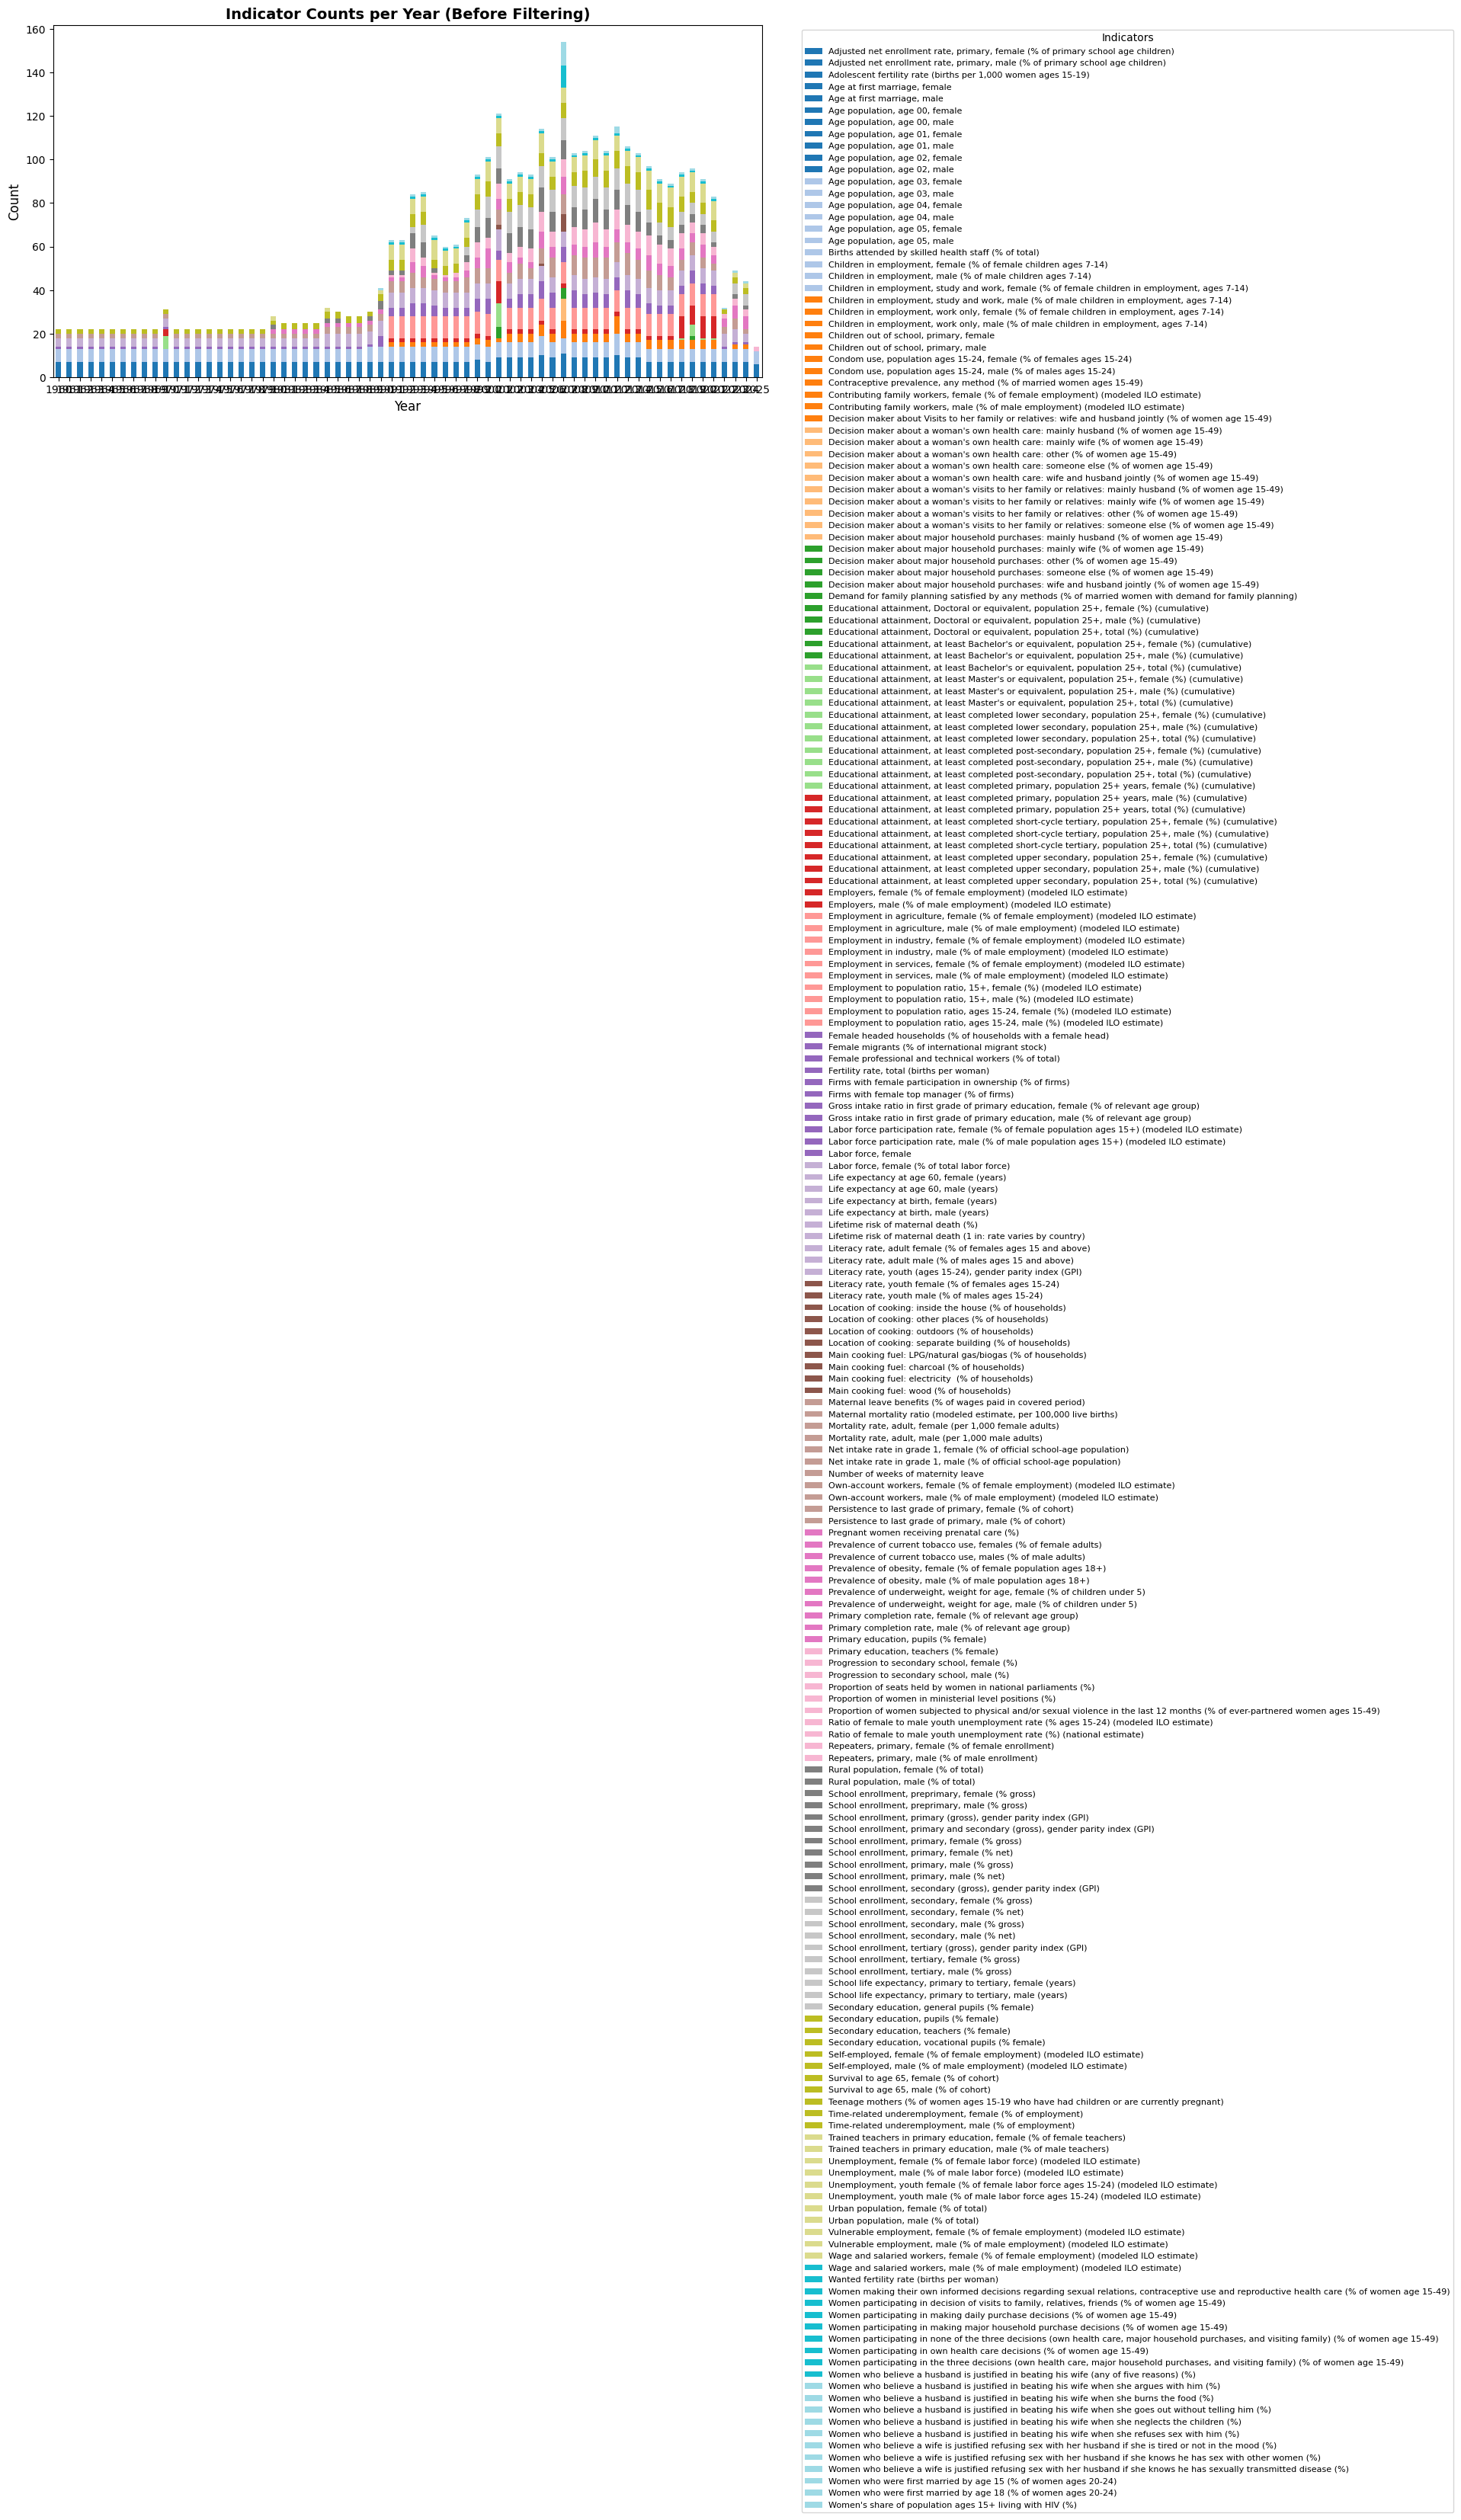

Shape (3808, 6)


In [16]:


# Create a pivot table / crosstab showing the count of each indicator per year
indicator_year_counts = pd.crosstab(df_filtered['Year'], df_filtered['Indicator Name'])

# print(indicator_year_counts)
# Plotting counts per year as a stacked bar chart
indicator_year_counts.plot(
    kind='bar', stacked=True, figsize=(12, 6), colormap='tab20'
)

plt.title('Indicator Counts per Year (After filtering)', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.legend(
    title='Indicators', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8
)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
print("Shape",df_filtered.shape)

# Create a pivot table / crosstab showing the count of each indicator per year
indicator_year_counts_unf = pd.crosstab(data['Year'], data['Indicator Name'])

# print(indicator_year_counts)
# Plotting counts per year as a stacked bar chart
indicator_year_counts_unf.plot(
    kind='bar', stacked=True, figsize=(12, 6), colormap='tab20'
)

plt.title('Indicator Counts per Year (Before Filtering)', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.legend(
    title='Indicators', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8
)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
print("Shape",data.shape)

In [17]:
df_filtered.to_csv('../data/processed/gender_indicators.csv', index=False)

# Analysing
The interesting points to analyze are:
- the global changes in different indicators (one graph per each)
    - age population (total number)
    - life expectancy
    - fertility
    - mortality rate
    - children out of school (finally no because 2022 doesn't have any information)
- the change in male/female ratio for different indicators
    - age population (total for female and total for male)
    - life expectancy at age 60 /at birth
    - mortality
    - survivial to age
    - school enrollement
It can be interesting to study age population apart because it forms a big part of dataset.

Lignes trouvées pour Fertility : 14
Lignes trouvées pour Life expectancy : 28
      Age population  Life expectancy  Fertility rate  Mortality rate
Year                                                                 
2018       2706545.0        46.449975          9.9080        173.8320
2019       2546482.0        46.739700          8.9270        170.0200
2020       2393701.0        46.055325          8.3485        173.2225
2021       2251809.0        44.537800          7.7825        188.6935
2022       1941245.0        46.597075          5.5840        202.1470
2023       1628461.0        47.180100          6.1770        193.8210
2024       1574254.0        48.457400          5.9635        160.4665
2025       1643038.0              NaN             NaN             NaN


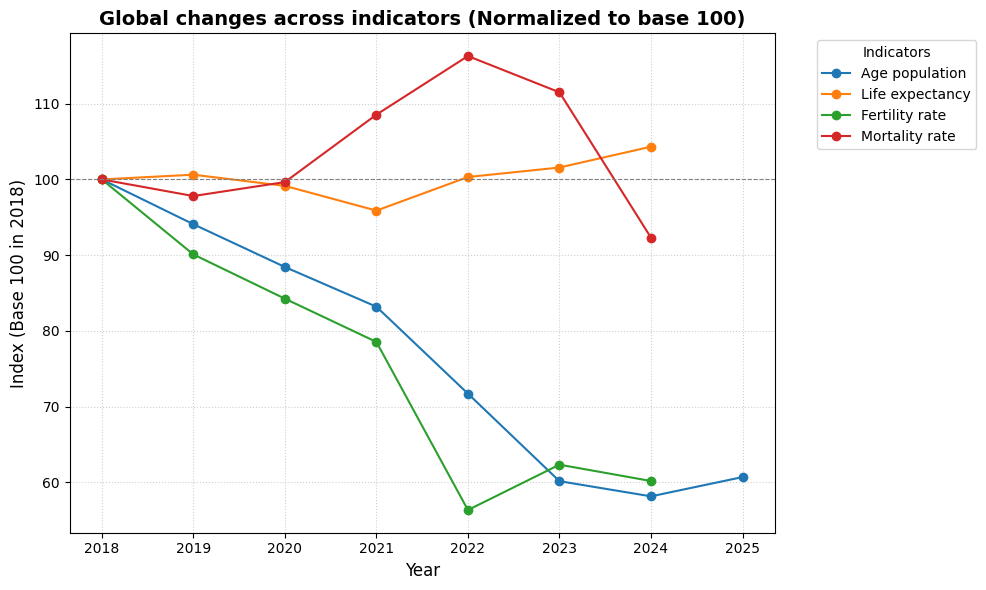

In [24]:

# S'assurer que la colonne 'Value' est bien en numérique
plot_index = df_filtered.copy()
plot_index['Value'] = pd.to_numeric(plot_index['Value'], errors='coerce')

# --- 1. Vérification et extraction pas à pas ---

# Pour la fertilité (attention au nom exact dans votre fichier)
fertility_df = plot_index[
    plot_index['Indicator Name'].str.contains('Fertility rate', case=False)
]
print('Lignes trouvées pour Fertility :', len(fertility_df))
fertility = fertility_df.groupby('Year')['Value'].mean()

# Pour l'espérance de vie
life_df = plot_index[
    plot_index['Indicator Name'].str.contains('Life expectancy', case=False)
]
print('Lignes trouvées pour Life expectancy :', len(life_df))
life_exp = life_df.groupby('Year')['Value'].mean()

# Somme pour l'âge
age_pop = (
    plot_index[
        plot_index['Indicator Name'].str.startswith('Age population')
    ]
    .groupby('Year')['Value']
    .sum()
)

# Mortalité
mortality = (
    plot_index[
        plot_index['Indicator Name'].str.contains('Mortality rate, adult')
    ]
    .groupby('Year')['Value']
    .mean()
)

# Création du DataFrame combiné
plot_transformed = pd.DataFrame(
    {
        'Age population': age_pop,
        'Life expectancy': life_exp,
        'Fertility rate': fertility,
        'Mortality rate': mortality,
    }
)

print(plot_transformed)  # Vérifiez si les colonnes contiennent des chiffres ou des NaN

# --- 2. SOLUTION RECOMMANDÉE : Normalisation (Indice 100) ---
# Indispensable car la population (ex: 200,000) et la fertilité (ex: 1.2)
# n'ont pas du tout la même échelle !
plot_normalized = (plot_transformed / plot_transformed.iloc[0]) * 100

# Tracé
plot_normalized.plot(figsize=(10, 6), marker='o')

plt.axhline(100, color='gray', linestyle='--', linewidth=0.8)
plt.title(
    'Global changes across indicators (Normalized to base 100)',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Index (Base 100 in 2018)', fontsize=12)
plt.legend(title='Indicators', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

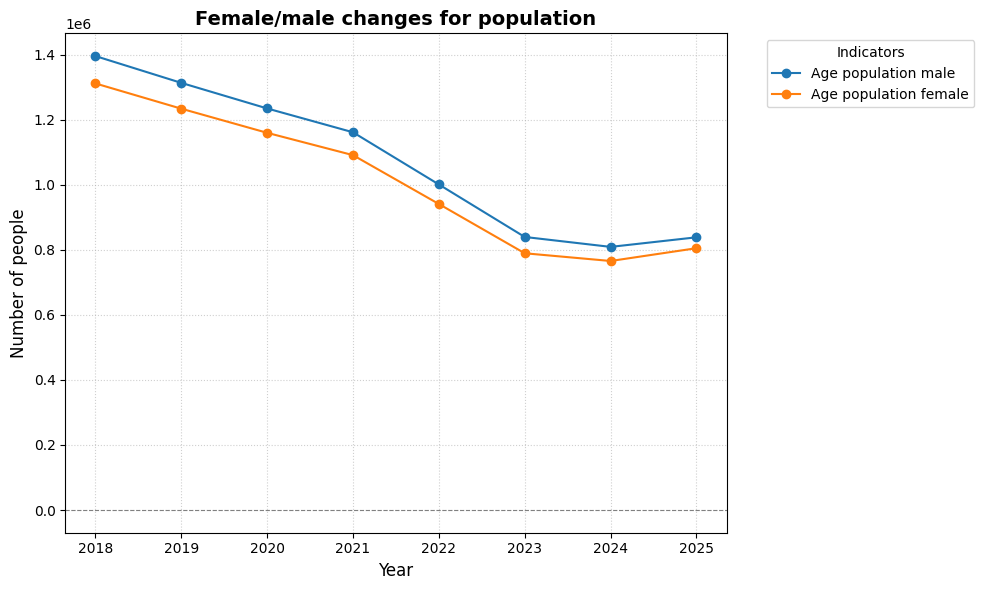

In [26]:
# Version plus robuste avec .str.contains()
mask_age = plot_index["Indicator Name"].str.startswith("Age population")

age_pop_male = (
    plot_index[
        mask_age & plot_index["Indicator Name"].str.contains(", male")
    ]
    .groupby("Year")["Value"]
    .sum()
)

age_pop_female = (
    plot_index[
        mask_age & plot_index["Indicator Name"].str.contains(", female")
    ]
    .groupby("Year")["Value"]
    .sum()
)

plot_transformed = pd.DataFrame(
    {
        'Age population male': age_pop_male,
        'Age population female': age_pop_female,

    }
)
plot_transformed.plot(figsize=(10, 6), marker='o')

plt.axhline(100, color='gray', linestyle='--', linewidth=0.8)
plt.title(
    'Female/male changes for population',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of people', fontsize=12)
plt.legend(title='Indicators', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()




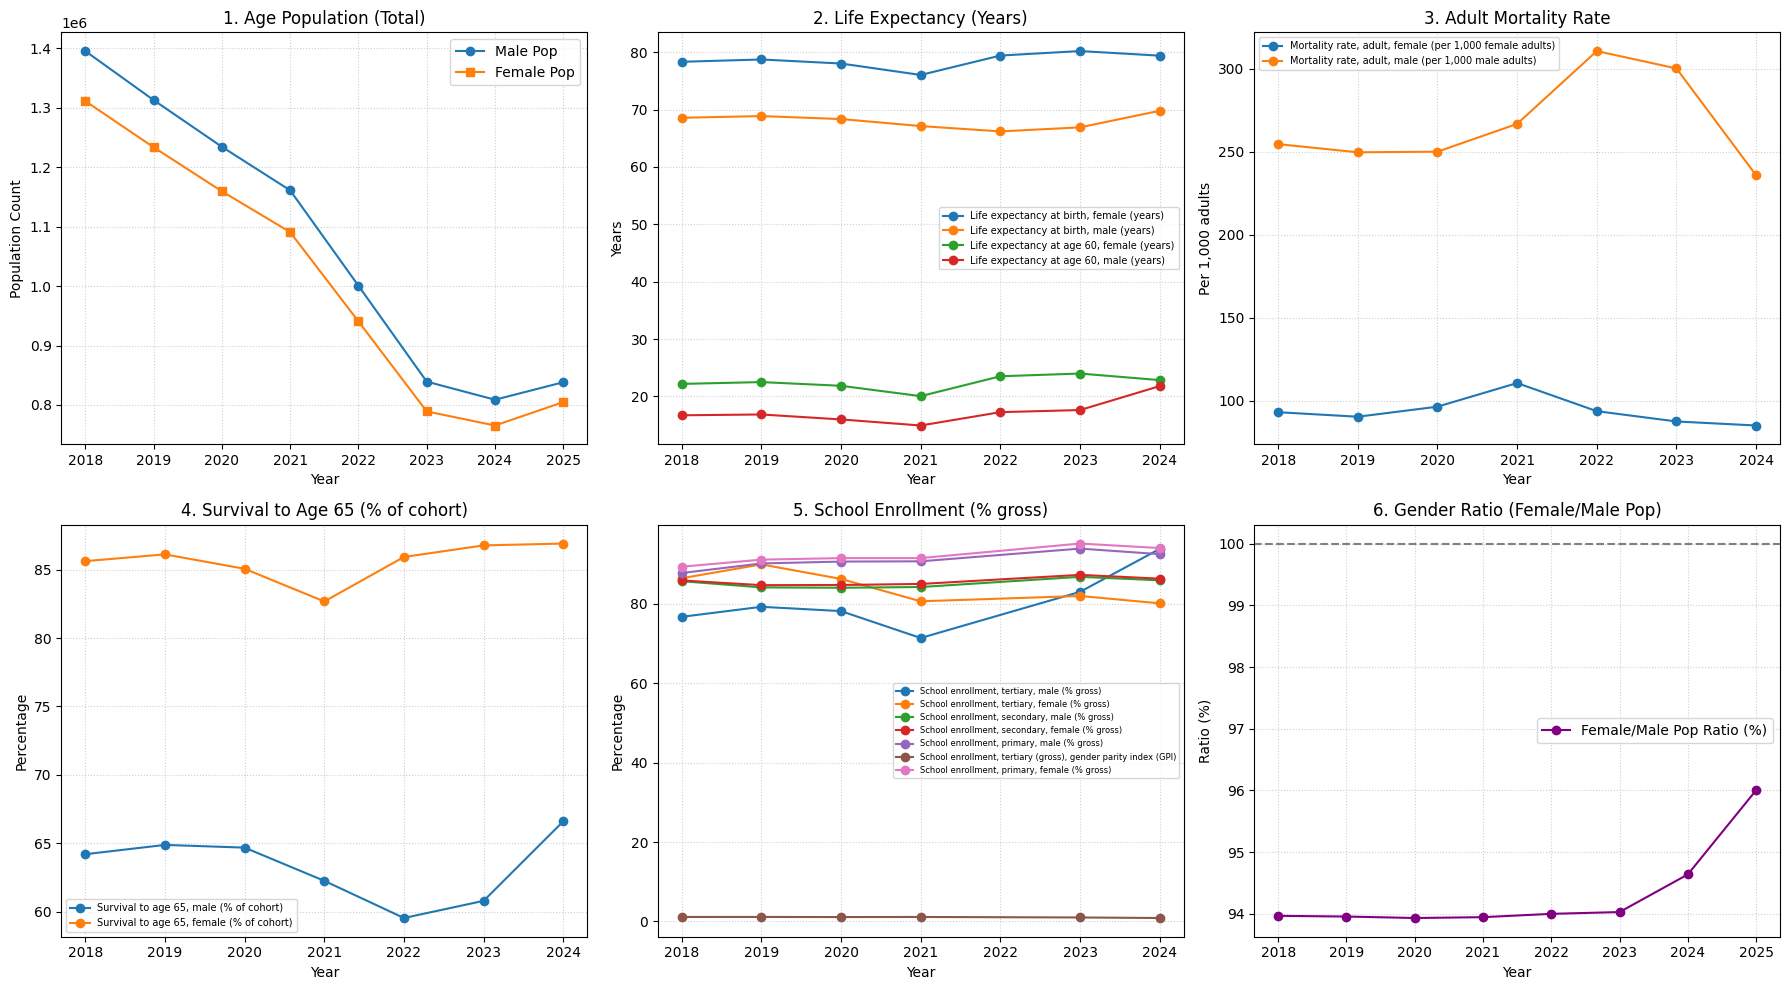

In [ ]:

df = df_filtered.copy()
df["Value"] = pd.to_numeric(df["Value"], errors="coerce")

# Création d'une grille de 2 lignes et 3 colonnes
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

# --- 1. Age Population (Total Male vs Female) ---
mask_age = df["Indicator Name"].str.startswith("Age population")
pop_m = (
    df[mask_age & df["Indicator Name"].str.contains(", male")]
    .groupby("Year")["Value"]
    .sum()
)
pop_f = (
    df[mask_age & df["Indicator Name"].str.contains(", female")]
    .groupby("Year")["Value"]
    .sum()
)
axes[0].plot(pop_m.index, pop_m.values, marker="o", label="Male Pop")
axes[0].plot(pop_f.index, pop_f.values, marker="s", label="Female Pop")
axes[0].set_title("1. Age Population (Total)")
axes[0].set_ylabel("Population Count")
axes[0].legend()
axes[0].grid(True, linestyle=":", alpha=0.6)

# --- 2. Life Expectancy (Birth & Age 60) ---
le_df = df[df["Indicator Name"].str.contains("Life expectancy")]
for ind in le_df["Indicator Name"].unique():
    sub = le_df[le_df["Indicator Name"] == ind].set_index("Year")["Value"]
    axes[1].plot(sub.index, sub.values, marker="o", label=ind)
axes[1].set_title("2. Life Expectancy (Years)")
axes[1].set_ylabel("Years")
axes[1].legend(fontsize=7)
axes[1].grid(True, linestyle=":", alpha=0.6)

# --- 3. Mortality Rate ---
mort_df = df[df["Indicator Name"].str.contains("Mortality rate, adult")]
for ind in mort_df["Indicator Name"].unique():
    sub = mort_df[mort_df["Indicator Name"] == ind].set_index("Year")["Value"]
    axes[2].plot(sub.index, sub.values, marker="o", label=ind)
axes[2].set_title("3. Adult Mortality Rate")
axes[2].set_ylabel("Per 1,000 adults")
axes[2].legend(fontsize=7)
axes[2].grid(True, linestyle=":", alpha=0.6)

# --- 4. Survival to Age 65 ---
surv_df = df[df["Indicator Name"].str.contains("Survival to age 65")]
for ind in surv_df["Indicator Name"].unique():
    sub = surv_df[surv_df["Indicator Name"] == ind].set_index("Year")["Value"]
    axes[3].plot(sub.index, sub.values, marker="o", label=ind)
axes[3].set_title("4. Survival to Age 65 (% of cohort)")
axes[3].set_ylabel("Percentage")
axes[3].legend(fontsize=7)
axes[3].grid(True, linestyle=":", alpha=0.6)

# --- 5. School Enrollment ---
sch_df = df[df["Indicator Name"].str.contains("School enrollment")]
for ind in sch_df["Indicator Name"].unique():
    sub = sch_df[sch_df["Indicator Name"] == ind].set_index("Year")["Value"]
    axes[4].plot(sub.index, sub.values, marker="o", label=ind)
axes[4].set_title("5. School Enrollment (% gross)")
axes[4].set_ylabel("Percentage")
axes[4].legend(fontsize=6)
axes[4].grid(True, linestyle=":", alpha=0.6)

# --- 6. Summary / Gender Gap Index or Ratio ---
# Exemple : Ratio de la population totale (Femme / Homme)
ratio_pop = (pop_f / pop_m) * 100
axes[5].plot(
    ratio_pop.index,
    ratio_pop.values,
    marker="o",
    color="purple",
    label="Female/Male Pop Ratio (%)",
)
axes[5].axhline(100, color="gray", linestyle="--")
axes[5].set_title("6. Gender Ratio (Female/Male Pop)")
axes[5].set_ylabel("Ratio (%)")
axes[5].legend()
axes[5].grid(True, linestyle=":", alpha=0.6)

# Mise en page générale
for ax in axes:
    ax.set_xlabel("Year")

plt.tight_layout()
plt.show()